<a href="https://colab.research.google.com/github/sebasmalvi-cell/Pr-ctica-Numpy/blob/main/Practica03_Perceptr%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PRACTICA 3**

**Nombre: Sebastián Vilaña**

**Fecha: 15 de noviembre de 2026**

**Materia: INTELIGENCIA ARTIFICIAL**

**Tema: El perceptrón**

Crear una matriz denominada X y un vector y con los siguientes datos: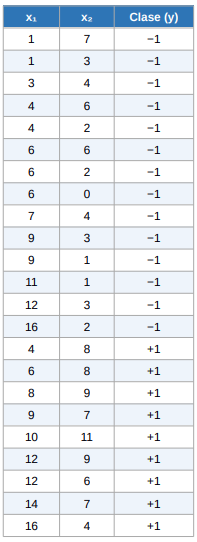

¿Qué representa cada fila de X? ¿Qué representa cada valor del vector y? ¿Por qué
este problema se considera de clasificación binaria?

In [1]:
X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2],
    [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9],
    [12, 6], [14, 7], [16, 4],
]
y = [-1] * 14 + [1] * 9

conteo = {-1: 0, 1: 0}
for etiqueta in y:
    conteo[etiqueta] += 1

print(f"Total de instancias = {len(X)}")
print(f"Variables de entrada = {len(X[0])} (x₁ y x₂)")
print(f"Número de clases = {len(conteo)}")
for etiqueta, cantidad in conteo.items():
    print(f"Clase {etiqueta:+d} → {cantidad} puntos")

Total de instancias = 23
Variables de entrada = 2 (x₁ y x₂)
Número de clases = 2
Clase -1 → 14 puntos
Clase +1 → 9 puntos


**Respuesta**

Cada fila de X representa un punto con dos coordenadas, y en esa misma posición de y se encuentra su clase asignada. En total conté 23 puntos, de los cuales 14 pertenecen a la clase −1 y 9 a la clase +1. Dado que únicamente existen dos clases, se trata de una clasificación binaria.

**Pregunta 1.b**

Pregunta guía: Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante
una sola recta? Justifica tu respuesta.

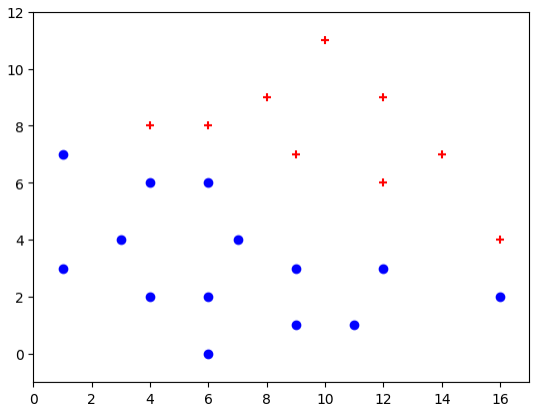

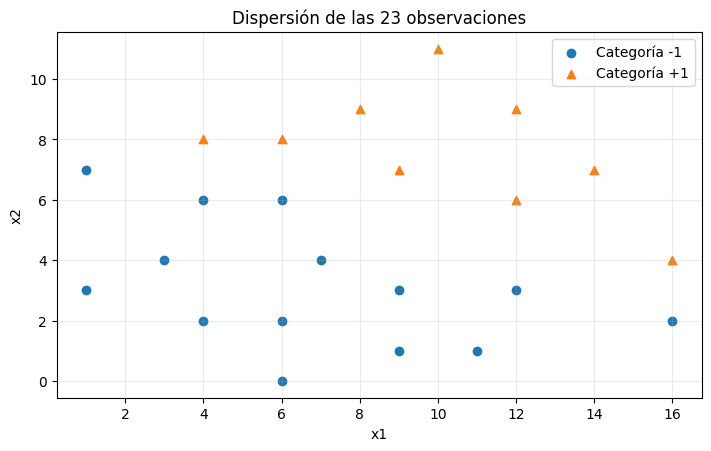

In [4]:
import matplotlib.pyplot as plt

def dibujar_muestras(eje, datos, etiquetas):
    x1_cat_neg, x2_cat_neg = [], []
    x1_cat_pos, x2_cat_pos = [], []

    for idx in range(len(datos)):
        coord_1, coord_2 = datos[idx]
        if etiquetas[idx] == -1:
            x1_cat_neg.append(coord_1)
            x2_cat_neg.append(coord_2)
        else:
            x1_cat_pos.append(coord_1)
            x2_cat_pos.append(coord_2)

    eje.scatter(x1_cat_neg, x2_cat_neg, marker="o", label="Categoría -1")
    eje.scatter(x1_cat_pos, x2_cat_pos, marker="^", label="Categoría +1")
    eje.set_xlabel("x1")
    eje.set_ylabel("x2")
    eje.grid(alpha=0.25)

lienzo, eje = plt.subplots(figsize=(7, 4.4), layout="constrained")
dibujar_muestras(eje, X, y)
eje.set_title("Dispersión de las 23 observaciones")
eje.legend()
plt.show()

**Respuesta**

Efectivamente, es posible dividir ambos grupos mediante una línea con pendiente negativa. Como muestra, cuando
𝑥
1
=4, dicha recta cruzaría el eje vertical en un rango de 6 a 8, mientras que al avanzar hacia
𝑥
1
=16, lo haría a una altura situada entre 2 y 4.

**Fase 2. Fundamento del Perceptrón**

**Actividad 2.a — Vector de pesos**

Crea una función llamada initialize_weights() que retorne tres pesos aleatorios pequeños. Los pesos deben generarse en un rango pequeño, por ejemplo entre -0.5 y 0.5.

Pregunta guía: ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene
dos variables? ¿Qué función cumple el bias en el modelo?


In [6]:
from random import Random

SEED = 13
rng = Random(SEED)

def crear_pesos_iniciales():
    valores = [rng.uniform(-0.5, 0.5) for _ in range(3)]
    return valores

pesos_base = crear_pesos_iniciales()
print("Pesos iniciales [w₀, w₁, w₂]")
print([round(val, 6) for val in pesos_base])

Pesos iniciales [w₀, w₁, w₂]
[-0.240992, 0.185258, 0.184082]


**Respuesta**

Hay dos pesos que van uno para cada entrada, y el tercero ($w_0$) funciona como el sesgo. Este último nos ayuda a mover la línea para que no tenga que pasar a la fuerza por el origen. Además, fijé la semilla en 13 para que, si vuelvo a correr el cuaderno, me salgan exactamente los mismos pesos iniciales.

**Actividad 2.b — Función de activación**

Pregunta guía: ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?


In [7]:
def escalon(valor_z):
    resultado = 1 if valor_z >= 0 else -1
    return resultado

for muestra in [-2, 0, 2]:
    prediccion = escalon(muestra)
    print(f"z = {muestra:+d} -> clase {prediccion:+d}")

z = -2 -> clase -1
z = +0 -> clase +1
z = +2 -> clase +1


**Respuesta**

Usar −1 y +1 hace que ambos tipos de error tengan la misma magnitud pero signo opuesto. Cuando la clase real es +1 y predice −1, la diferencia da 2, y al revés da −2. De este modo, el ajuste empuja la suma hacia arriba o hacia abajo según cómo haya fallado, y si la suma es cero, retorna +1.

**Pregunta 2.c — Cálculo de salida**

 ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Porqué no basta con calcular solo z?

In [14]:
def combinar_entradas(entrada, pesos):
    val_1, val_2 = entrada
    sesgo, p1, p2 = pesos
    return sesgo + p1 * val_1 + p2 * val_2

def escalon(valor_z):
    return 1 if valor_z >= 0 else -1

def evaluar_perceptron(entrada, pesos):
    total = combinar_entradas(entrada, pesos)
    return escalon(total)

pesos_fijos = [-2, 0, 0.5]
for pos in [1, 2, 14]:
    muestra = X[pos]
    z = combinar_entradas(muestra, pesos_fijos)
    salida = evaluar_perceptron(muestra, pesos_fijos)
    print(f"{muestra} -> z = {z:+.1f}, predicción = {salida:+d}, clase real = {y[pos]:+d}")

[1, 3] -> z = -0.5, predicción = -1, clase real = -1
[3, 4] -> z = +0.0, predicción = +1, clase real = -1
[4, 8] -> z = +2.0, predicción = +1, clase real = +1


**Respuesta**

El valor de "z" puede ser cualquiera, y la activación solo revisa su signo para asignar la clase. Usando los pesos de prueba obtuve −0.5, 0 y 2 en los tres puntos, lo que dio predicciones de −1, +1 y +1; el segundo falló porque en realidad era −1.

**Fase 3. Visualización de la Frontera de Decisión**

**Actividad 3.a — Función de graficación**

 ¿Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si los pesos iniciales son aleatorios?


In [34]:
def graficar_frontera(ejes, datos, clases, pesos, titulo):
    graficar_puntos(ejes, datos, clases)
    sesgo, peso1, peso2 = pesos
    lim_x_min = min(fila[0] for fila in datos) - 1
    lim_x_max = max(fila[0] for fila in datos) + 1
    lim_y_min = min(fila[1] for fila in datos) - 1
    lim_y_max = max(fila[1] for fila in datos) + 1
    ejes.set(xlim=(lim_x_min, lim_x_max), ylim=(lim_y_min, lim_y_max), title=titulo)

    if peso2 != 0:
        eje_x = [lim_x_min, lim_x_max]
        eje_y = [-(sesgo + peso1 * val) / peso2 for val in eje_x]
        ejes.plot(eje_x, eje_y, color="#262626", lw=1.7, label="Frontera")
    elif peso1 != 0:
        ejes.axvline(-sesgo / peso1, color="#262626", lw=1.7, label="Frontera vertical")
    else:
        ejes.text(0.03, 0.06, f"Salida constante ({activation(sesgo):+d})",
                transform=ejes.transAxes)

def visualizar_perceptron(datos, clases, pesos, titulo):
    figura, ejes = plt.subplots(figsize=(7, 4.4), layout="constrained")
    graficar_frontera(ejes, datos, clases, pesos, titulo)
    ejes.legend()
    plt.show()

**Respuesta**

Esa línea muestra los puntos donde $z$ es igual a cero, dejando valores positivos a un lado y negativos al otro. Cuando $w_2$ es cero y $w_1$ no lo es, se despeja $x_1$ y queda una línea vertical. Al inicio, dónde queda ubicada esta recta depende de los pesos aleatorios con los que partimos.   

**Actividad 3.b — Gráfica con pesos iniciales**

¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?



Errores con los pesos iniciales = 14/23


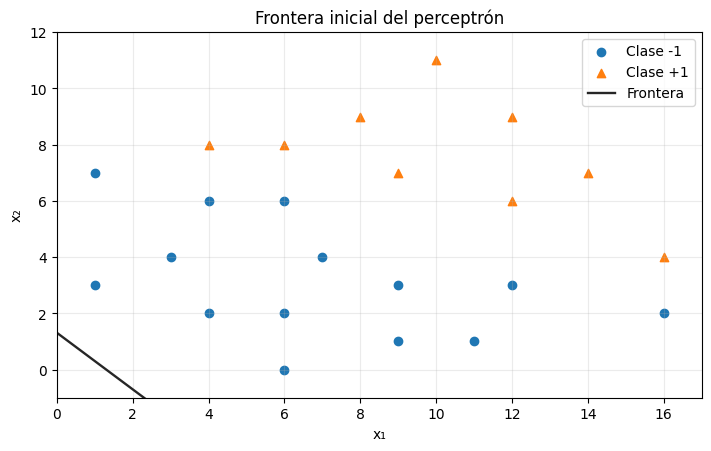

In [35]:
conteo_fallos = 0
for pos in range(len(X)):
    if perceptron_compute(X[pos], w_initial) != y[pos]:
        conteo_fallos += 1
print(f"Errores con los pesos iniciales = {conteo_fallos}/{len(X)}")
visualizar_perceptron(X, y, w_initial, "Frontera inicial del perceptrón")

**Respuesta**

Con los pesos iniciales quedan 14 de 23 muestras mal clasificadas porque el modelo aún no ha sido entrenado con las etiquetas reales para mover la frontera.

**Fase 4. Entrenamiento del Perceptrón**

**Actividad 4.a — Implementación de la función de aprendizaje**

¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?



In [39]:
def aprendizaje_perceptron(muestras, clases, pesos_base, factor_lr, iter_max):
    w_actual = pesos_base.copy()
    seq_pesos = []
    seq_errores = []
    num_cambios = 0

    for _ in range(iter_max):
        fallos = 0
        for x_item, y_item in zip(muestras, clases):
            pred = perceptron_compute(x_item, w_actual)
            if pred != y_item:
                paso = factor_lr * (y_item - pred)
                w_actual[0] += paso
                w_actual[1] += paso * x_item[0]
                w_actual[2] += paso * x_item[1]
                fallos += 1
                num_cambios += 1

        seq_errores.append(fallos / len(muestras))
        seq_pesos.append(w_actual.copy())
        if fallos == 0:
            break

    return w_actual, len(seq_errores), num_cambios, seq_pesos, seq_errores

**Respuesta***

El límite de épocas impide un bucle infinito; cuando los datos no son linealmente separables, siempre persistirá algún error y el ajuste de pesos se detendrá al alcanzar ese tope.

**Actividad 4.b — Registro del error**

¿Qué significa que la tasa de error llegue a cero?



In [40]:
_, _, _, pesos_epocas, errores_epocas = aprendizaje_perceptron(
    X, y, w_initial, factor_lr=0.5, iter_max=5
)
for idx_ep, tasa_err in enumerate(errores_epocas, start=1):
    print(f"Época {idx_ep} → {tasa_err:.2%} de error")

Época 1 → 8.70% de error
Época 2 → 13.04% de error
Época 3 → 8.70% de error
Época 4 → 13.04% de error
Época 5 → 8.70% de error


**Respuesta**

Eso indica que durante esa época se clasificaron correctamente los 23 puntos; al no presentarse errores, los pesos no tuvieron ajustes y permanecieron sin cambios.

**Actividad 4.c — Registro de pesos**

 ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?



In [41]:
for idx_ep, vector_w in enumerate(pesos_epocas, start=1):
    print(f"Época {idx_ep} → {[round(val, 4) for val in vector_w]}")

Época 1 → [-0.241, 3.1853, 1.1841]
Época 2 → [-1.241, 0.1853, 0.1841]
Época 3 → [-1.241, 3.1853, 1.1841]
Época 4 → [-2.241, 0.1853, 2.1841]
Época 5 → [-2.241, 3.1853, 3.1841]


**Respuesta**

Guardar una copia independiente por época permite conservar el estado exacto de los pesos en cada iteración; de lo contrario, al modificar la lista en el lugar, todo el historial terminaría reflejando únicamente los valores finales.

**Fase 5. Entrenamiento con tasa de aprendizaje 0.5**

**Actividad 5.a — Entrena el modelo**

 ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?




In [42]:
w_inicio = w_initial.copy()
w_final, total_epocas, total_updates, hist_w, hist_err = aprendizaje_perceptron(
    X, y, w_inicio, factor_lr=0.5, iter_max=1000
)

print(f"Pesos iniciales = {[round(val, 6) for val in w_inicio]}")
print(f"Pesos finales = {[round(val, 6) for val in w_final]}")
print(f"Épocas = {total_epocas}")
print(f"Actualizaciones = {total_updates}")
print(f"Error final = {hist_err[-1]:.2%}")

Pesos iniciales = [-0.240992, 0.185258, 0.184082]
Pesos finales = [-29.240992, 1.185258, 3.184082]
Épocas = 54
Actualizaciones = 143
Error final = 0.00%


**Respuesta**

Convergió en la época 54 tras 143 actualizaciones de pesos; el error final registrado es 0% y la frontera separa ambas clases en lados opuestos.

**Actividad 5.b — Frontera final**

 ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?



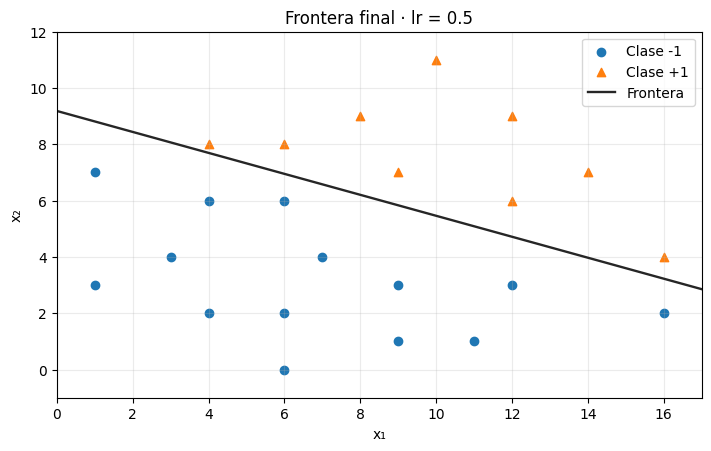

In [44]:
visualizar_perceptron(X, y, w_final, "Frontera final · lr = 0.5")

**Respuesta**

La frontera final logra separar correctamente los 23 puntos; en comparación con la inicial, se ubica más arriba y con menor inclinación, pasando de una pendiente aproximada de −1.01 a −0.37.

**Fase 6. Predicción con Nuevas Instancias**

**6.1 Actividades de predicción**

 ¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?



In [45]:
from IPython.display import Markdown, display

muestras_prueba = [[5, 5], [10, 6], [6, 10]]
predicciones_prueba = []
for muestra in muestras_prueba:
    predicciones_prueba.append(perceptron_compute(muestra, w_final))

lineas_tabla = ["| Instancia | Salida predicha |", "|---|---:|"]
for muestra, clase_pred in zip(muestras_prueba, predicciones_prueba):
    lineas_tabla.append(f"| `{muestra}` | {clase_pred:+d} |")
display(Markdown("\n".join(lineas_tabla)))

| Instancia | Salida predicha |
|---|---:|
| `[5, 5]` | -1 |
| `[10, 6]` | +1 |
| `[6, 10]` | +1 |

**Respuesta**

Sí; [5, 5] se ubicó por debajo de la frontera y obtuvo −1, mientras que [10, 6] y [6, 10] quedaron por encima y recibieron +1.

**Actividad 6.b — Dataset extendido**

¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna
predicción parece discutible? Justifica tu respuesta.

Total del conjunto extendido = 26


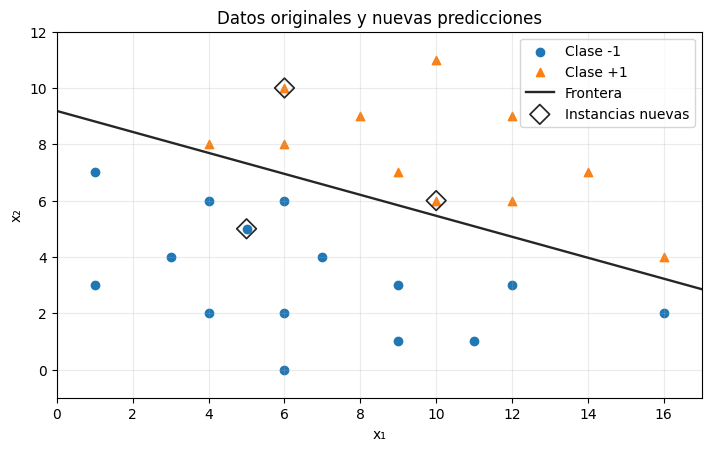

In [46]:
datos_ampliados = X + muestras_prueba
clases_ampliadas = y + predicciones_prueba
print(f"Total del conjunto extendido = {len(datos_ampliados)}")

lienzo, ejes = plt.subplots(figsize=(7, 4.4), layout="constrained")
graficar_frontera(ejes, datos_ampliados, clases_ampliadas, w_final, "Datos originales y nuevas predicciones")
ejes.scatter(
    [muestra[0] for muestra in muestras_prueba], [muestra[1] for muestra in muestras_prueba],
    marker="D", s=100, facecolors="none", edgecolors="#262626",
    linewidths=1.25, label="Instancias nuevas", zorder=4,
)
ejes.legend()
plt.show()

**Respuesta**

La muestra que requiere mayor análisis es [10, 6]: fue clasificada como +1, pero se encuentra a cerca de 0.54 unidades por encima de la frontera en el eje vertical, por lo que un ligero desplazamiento hacia arriba de la recta bastaría para que cambie de categoría. Asimismo, el gráfico refleja las predicciones del modelo al no disponerse de las etiquetas verdaderas de estas tres nuevas instancias.

**Fase 7. Evolución de la Frontera de Decisión**

**Actividad 7.a — Seis estados del entrenamiento**

 ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?



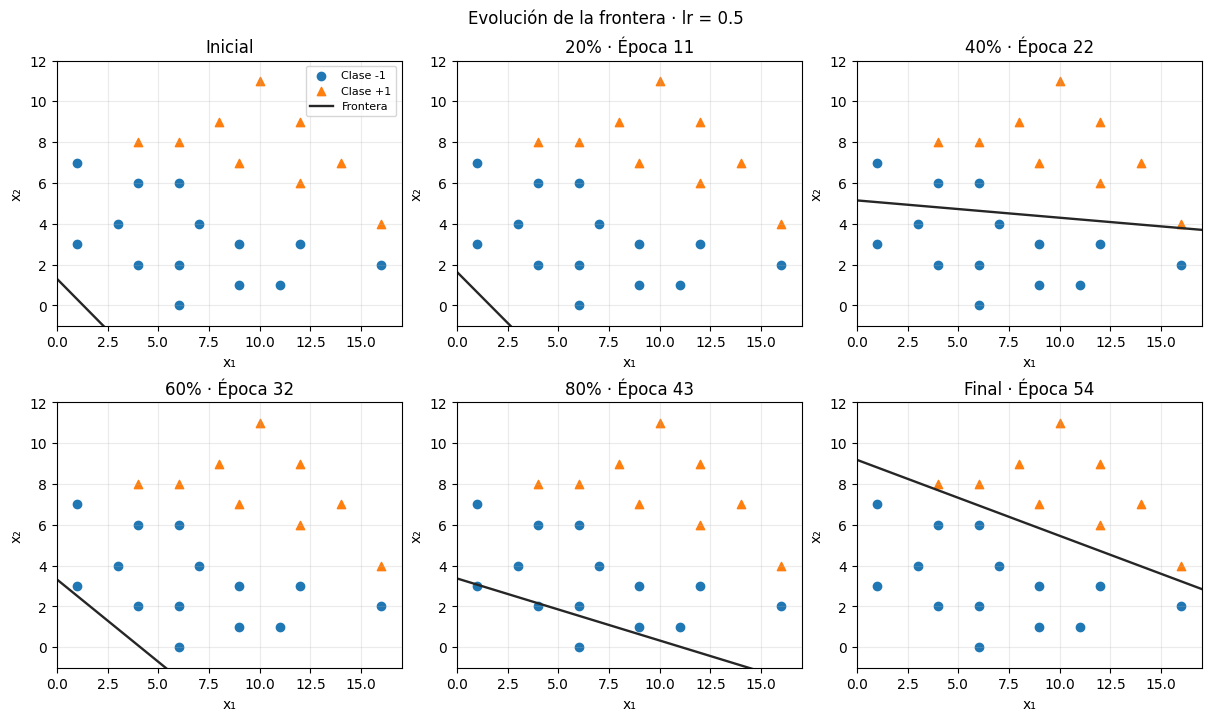

In [48]:
def estados_entrenamiento(w_base, registro_w):
    total_ep = len(registro_w)
    lista_pesos = [w_base] + registro_w
    fases = [("Inicial", w_base)]
    if total_ep < 6:
        for num_ep in range(1, total_ep + 1):
            fases.append((f"Época {num_ep}", lista_pesos[num_ep]))
        return fases

    for pct in [20, 40, 60, 80]:
        num_ep = round(total_ep * pct / 100)
        fases.append((f"{pct}% · Época {num_ep}", lista_pesos[num_ep]))
    fases.append((f"Final · Época {total_ep}", lista_pesos[-1]))
    return fases

def graficar_evolucion(datos, clases, w_base, registro_w, titulo):
    fases = estados_entrenamiento(w_base, registro_w)
    num_filas = (len(fases) + 2) // 3
    lienzo, rejilla = plt.subplots(num_filas, 3, figsize=(12, 3.15 * num_filas + 0.8),
                                   squeeze=False, layout="constrained")
    rejilla = rejilla.flatten()
    for idx in range(len(fases)):
        etiqueta_sub, vector_w = fases[idx]
        graficar_frontera(rejilla[idx], datos, clases, vector_w, etiqueta_sub)
    for idx in range(len(fases), len(rejilla)):
        rejilla[idx].set_visible(False)

    lienzo.suptitle(titulo)
    rejilla[0].legend(loc="upper right", fontsize=8)
    plt.show()

graficar_evolucion(X, y, w_inicio, hist_w, "Evolución de la frontera · lr = 0.5")

**Respuesta**

La frontera avanza a saltos a medida que se actualizan los pesos: cerca del 40 % luce casi horizontal, hacia el 60 % retoma mayor inclinación y en la etapa final se ubica más arriba separando ambos grupos.

**Actividad 7.b — Interpretación geométrica**

 ¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?


In [49]:
lineas_tabla = ["| Estado | Pendiente | Intercepto en x₂ |", "|---|---:|---:|"]
for fase, (b0, b1, b2) in estados_entrenamiento(w_inicio, hist_w):
    if b2 != 0:
        lineas_tabla.append(f"| {fase} | {-b1 / b2:.3f} | {-b0 / b2:.3f} |")
    else:
        lineas_tabla.append(f"| {fase} | Sin pendiente finita | — |")
display(Markdown("\n".join(lineas_tabla)))

| Estado | Pendiente | Intercepto en x₂ |
|---|---:|---:|
| Inicial | -1.006 | 1.309 |
| 20% · Época 11 | -1.000 | 1.646 |
| 40% · Época 22 | -0.085 | 5.147 |
| 60% · Época 32 | -0.807 | 3.326 |
| 80% · Época 43 | -0.304 | 3.374 |
| Final · Época 54 | -0.372 | 9.183 |

**Respuesta**

La inclinación de la frontera depende de la relación entre los pesos de entrada ($-w_1 / w_2$). Al mantener fijo $w_2$, variar el sesgo desplaza el corte con el eje $x_2$, y si además $w_1$ permanece constante, la recta se traslada en paralelo sin modificar su inclinación.

**Fase 8. Evolución del Error**

**Actividad 8.a — Gráfica de error**

¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?



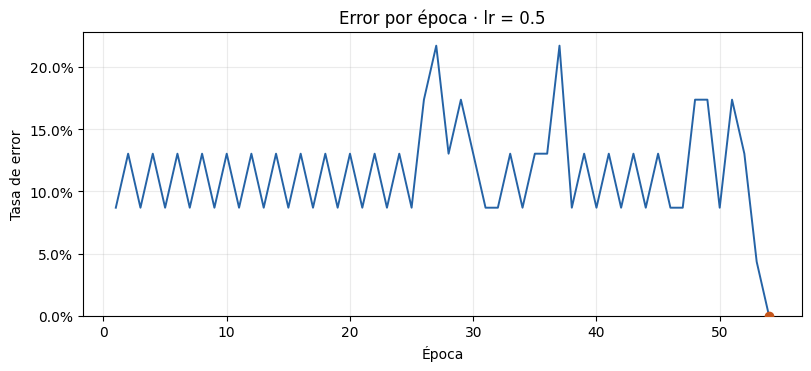

In [50]:
from matplotlib.ticker import PercentFormatter

def graficar_error(serie_err, titulo):
    ciclos = range(1, len(serie_err) + 1)
    lienzo, ejes = plt.subplots(figsize=(8, 3.6), layout="constrained")
    ejes.plot(ciclos, serie_err, color="#2563a6", lw=1.4)
    ejes.scatter(len(serie_err), serie_err[-1], color="#c4551a", zorder=3)
    ejes.set(xlabel="Época", ylabel="Tasa de error", title=titulo, ylim=(0, None))
    ejes.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ejes.grid(alpha=0.25)
    plt.show()

graficar_error(hist_err, "Error por época · lr = 0.5")

**Respuesta**

El error oscila porque cada ajuste corrige una muestra pero puede desplazar la frontera y dejar otra mal clasificada; por eso se pasa de 2 errores en la primera época a 3 en la segunda.

**Actividad 8.b — Análisis de convergencia**

 ¿Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta.

 **Respuesta**

 Un error nulo indica que se clasificaron correctamente todas las muestras de entrenamiento, mientras que evaluar la generalización ante datos inéditos requiere contar con sus etiquetas reales.



**Fase 9. Comparación de Tasas de Aprendizaje**

**Actividad 9.a — Entrenamiento comparativo**

 ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?




In [60]:
tasas_lr = [0.3, 0.5, 0.8]
pesos_comunes = w_inicio.copy()
experimentos_lr = {}

for tasa in tasas_lr:
    experimentos_lr[tasa] = aprendizaje_perceptron(
        X, y, pesos_comunes.copy(), tasa, 1000
    )

print(f"Pesos iniciales comunes = {[round(val, 6) for val in pesos_comunes]}")

Pesos iniciales comunes = [-0.240992, 0.185258, 0.184082]


**Respuesta**

Fijar los mismos pesos iniciales y el mismo orden de muestras aísla el efecto de la tasa de aprendizaje, permitiendo comparar directamente cómo varía la trayectoria y la convergencia.

**Actividad 9.b — Gráficas comparativas**

 ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?



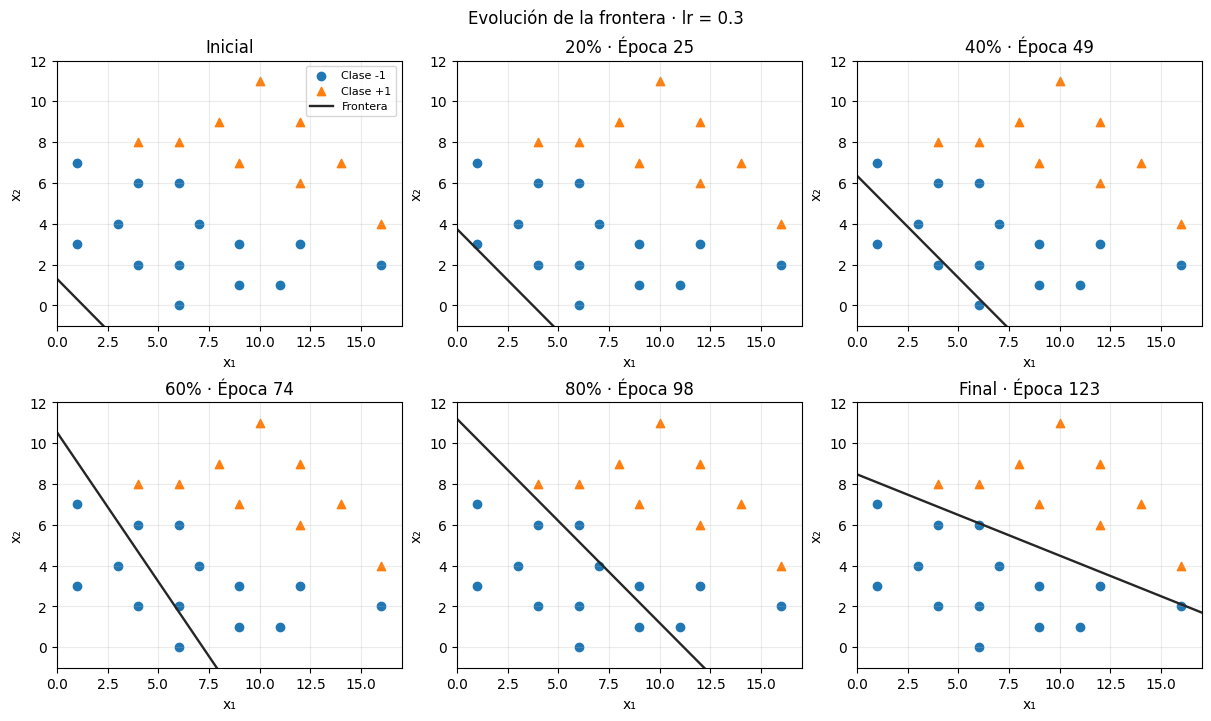

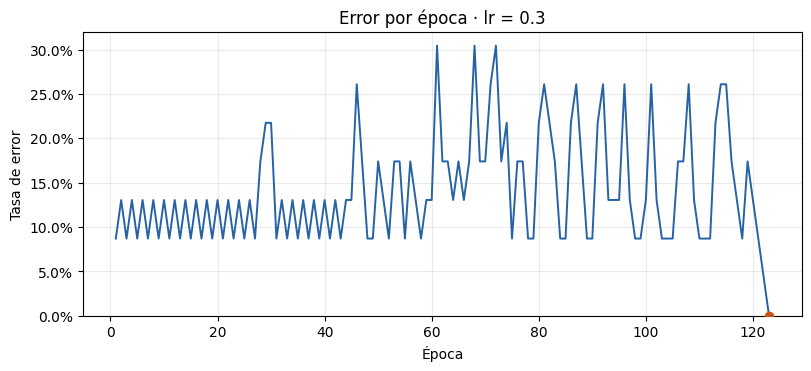

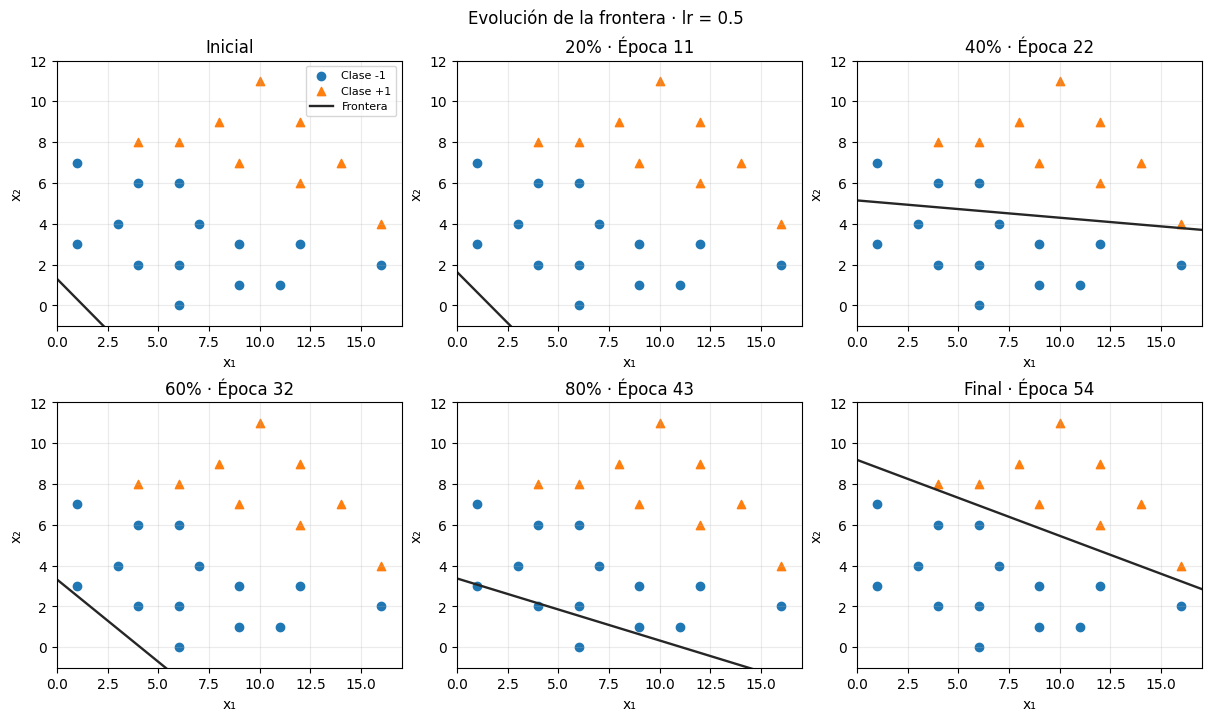

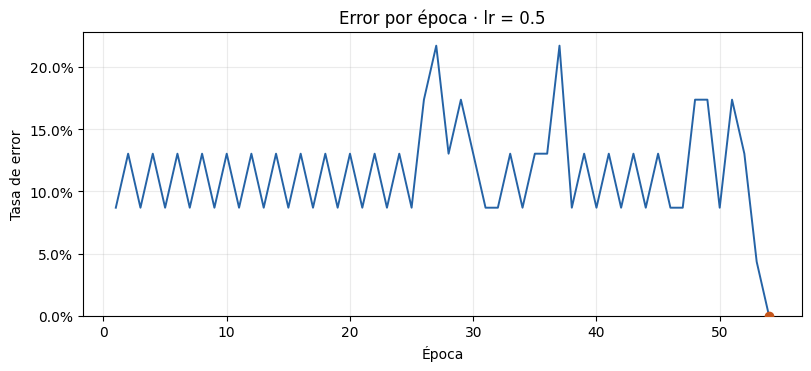

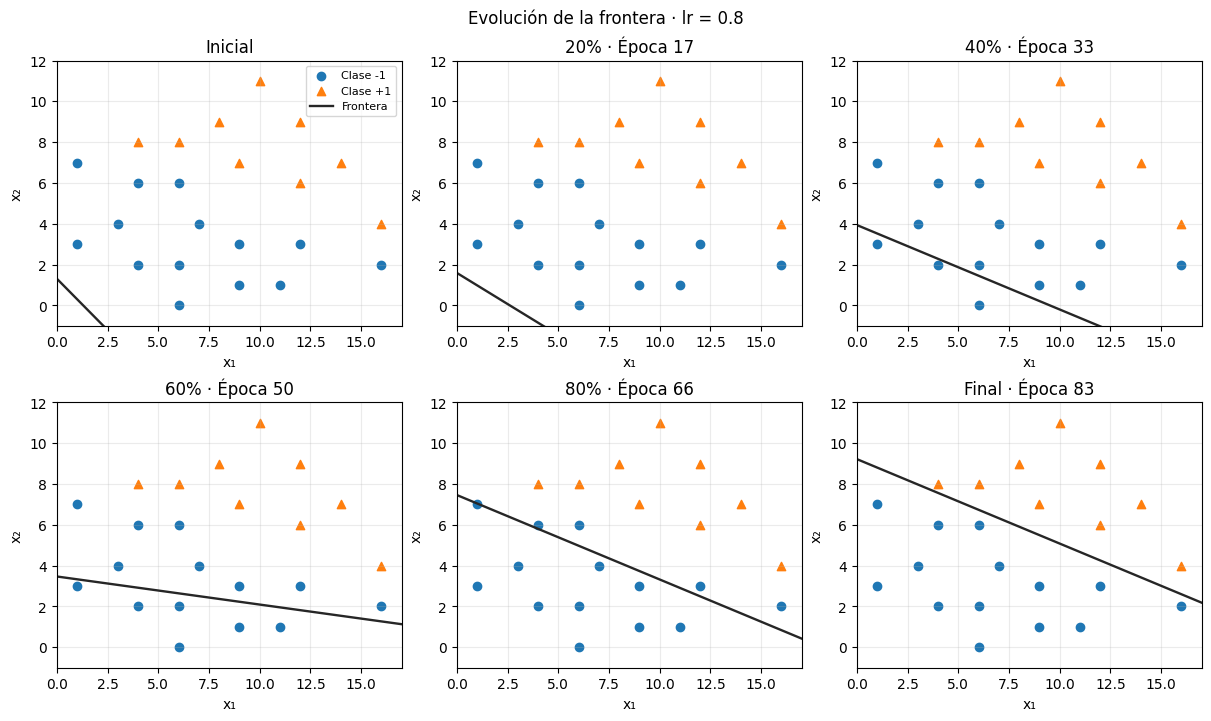

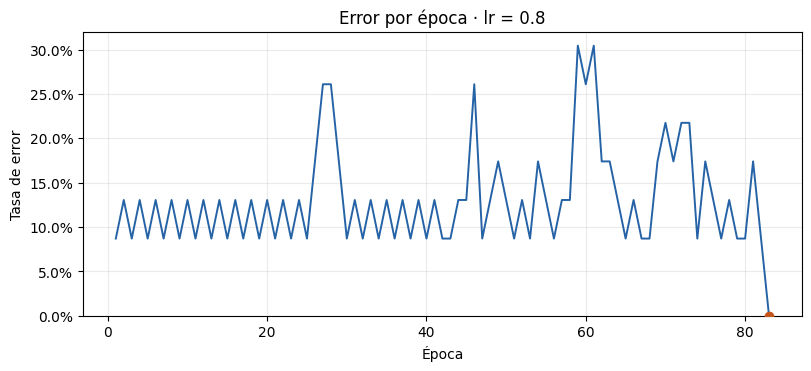

In [61]:
for tasa in tasas_lr:
    _, _, _, registro_w, serie_err = experimentos_lr[tasa]
    graficar_evolucion(X, y, pesos_comunes, registro_w, f"Evolución de la frontera · lr = {tasa}")
    graficar_error(serie_err, f"Error por época · lr = {tasa}")

**Respuesta**

En esta configuración, 0.5 converge en 54 épocas frente a 83 con 0.8 y 123 con 0.3, aunque el rendimiento relativo depende de los pesos iniciales, el orden de los datos y la geometría del conjunto.

**Actividad 9.c — Tabla comparativa**

 ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?



In [62]:
filas = [
    "| lr | Épocas | Actualizaciones | Error final | Pesos finales [w₀, w₁, w₂] |",
    "|---:|---:|---:|---:|---|",
]
for tasa, (pesos, epocas, cambios, _, serie_err) in experimentos_lr.items():
    pesos_texto = ", ".join(f"{val:.4f}" for val in pesos)
    filas.append(f"| {tasa} | {epocas} | {cambios} | {serie_err[-1]:.2%} | [{pesos_texto}] |")
display(Markdown("\n".join(filas)))

| lr | Épocas | Actualizaciones | Error final | Pesos finales [w₀, w₁, w₂] |
|---:|---:|---:|---:|---|
| 0.3 | 123 | 400 | 0.00% | [-42.2410, 1.9853, 4.9841] |
| 0.5 | 54 | 143 | 0.00% | [-29.2410, 1.1853, 3.1841] |
| 0.8 | 83 | 249 | 0.00% | [-75.4410, 3.3853, 8.1841] |

**Respuesta**

Los pesos finales difieren en cada experimento porque el margen de separación entre ambas clases admite múltiples hiperplanos capaces de clasificar correctamente todos los datos, y cada tasa de aprendizaje guía las actualizaciones por una trayectoria distinta hasta detenerse en el primer vector que logra error cero.

**Conclusiones**

La velocidad de convergencia y el número de épocas varían según la tasa de aprendizaje, ya que valores intermedios pueden alcanzar el error nulo en menos ciclos que tasas muy altas o muy bajas.

Diferentes tasas de aprendizaje pueden converger a vectores de pesos finales distintos con error cero cuando existe margen de separación entre clases, dado que distintas trayectorias de actualización pueden detenerse en rectas válidas diferentes.